# 03 · Model Training, Evaluation, and Comparison

**Goal:** Build, evaluate, and compare machine learning models to predict residential house sale prices from property attributes.

**Ground Rules & Leakage Prevention:**
- Target is `price`. Features are strictly limited to pre-sale property characteristics.
- Property-aware train/test split: grouped by `id` so repeat sales of the same house never appear in both sets.
- Log-transformation on the target: `log1p(price)` used during training; evaluations transformed back to real USD scale using `expm1`.
- Clean pipelines: Imputation, scaling, and categorical encoding are fitted strictly on training data inside scikit-learn `Pipeline` and `ColumnTransformer` objects.
- Models evaluated: Baseline (Median), Linear Regression, Ridge Regression, Random Forest Regressor, and HistGradientBoosting Regressor.

## 1. Setup & Environment

In [1]:
import sys
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import config, train, predict

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load Processed Data & Feature Schema

In [2]:
df = pd.read_csv(config.CLEAN_DATA_PATH)
print("Processed Dataset Shape:", df.shape)
print("Numeric Features:", len(train.NUMERIC_FEATURES))
print("Categorical Features:", len(train.CATEGORICAL_FEATURES))
print("Excluded Columns:", train.EXCLUDED_COLUMNS)

Processed Dataset Shape: (21613, 24)
Numeric Features: 20
Categorical Features: 1
Excluded Columns: ['id', 'sale_date', 'price']


## 3. Property-Aware Grouped Train/Test Split

In [3]:
X_train, y_train, X_test, y_test, split_info = train.split_data(df)
print("Train rows:", split_info["train_rows"], f"(unique properties: {split_info['train_unique_ids']})")
print("Test rows:", split_info["test_rows"], f"(unique properties: {split_info['test_unique_ids']})")
print("ID overlap count:", split_info["id_overlap_count"])

Train rows: 17289 (unique properties: 17148)
Test rows: 4324 (unique properties: 4288)
ID overlap count: 0


## 4. Run Training & Benchmarking Pipeline

In [4]:
# Train all 5 candidate models and calculate evaluation metrics
report = train.train_and_evaluate()


Model                    | MAE ($)      | RMSE ($)     | R²       | Fit Time  
--------------------------------------------------------------------------------
Baseline (Median)        | $   225,269 | $   385,665 |  -0.0649 |     0.00s
Linear Regression        | $    75,865 | $   166,770 |   0.8009 |     0.05s
Ridge Regression         | $    75,817 | $   164,330 |   0.8067 |     0.04s


Random Forest            | $    69,922 | $   128,629 |   0.8815 |     0.91s


HistGradientBoosting     | $    63,704 | $   120,140 |   0.8967 |     4.33s

Saved winning model pipeline to: /Users/adityapratapsingh/Desktop/RealEstate/REAL_ESTATE/models/price_model.joblib


Saved comparison figure to: /Users/adityapratapsingh/Desktop/RealEstate/REAL_ESTATE/reports/figures/11_model_performance_comparison.png
Saved residual diagnostics to: /Users/adityapratapsingh/Desktop/RealEstate/REAL_ESTATE/reports/figures/12_model_residuals_diagnostic.png
Saved metrics report to: /Users/adityapratapsingh/Desktop/RealEstate/REAL_ESTATE/models/model_metrics.json



## 5. Metrics Comparison Table (Real Dollar Scale & Log Scale)

In [5]:
metrics_df = pd.DataFrame(report["model_performance"]).T
display(metrics_df[["mae_dollar", "rmse_dollar", "r2", "mae_log", "rmse_log", "r2_log", "fit_time_seconds"]])

,mae_dollar,rmse_dollar,r2,mae_log,rmse_log,r2_log,fit_time_seconds
Baseline (Median),"225,269.18","385,664.53",-0.06,0.42,0.53,-0.01,0.00
Linear Regression,"75,865.49","166,770.00",0.80,0.13,0.18,0.88,0.05
Ridge Regression,"75,816.99","164,329.91",0.81,0.13,0.18,0.88,0.04
Random Forest,"69,922.41","128,629.26",0.88,0.13,0.18,0.89,0.91
HistGradientBoosting,"63,704.03","120,139.77",0.90,0.11,0.16,0.91,4.33


## 6. Model Diagnostics & Visualizations

Candidate Model Comparison Chart:


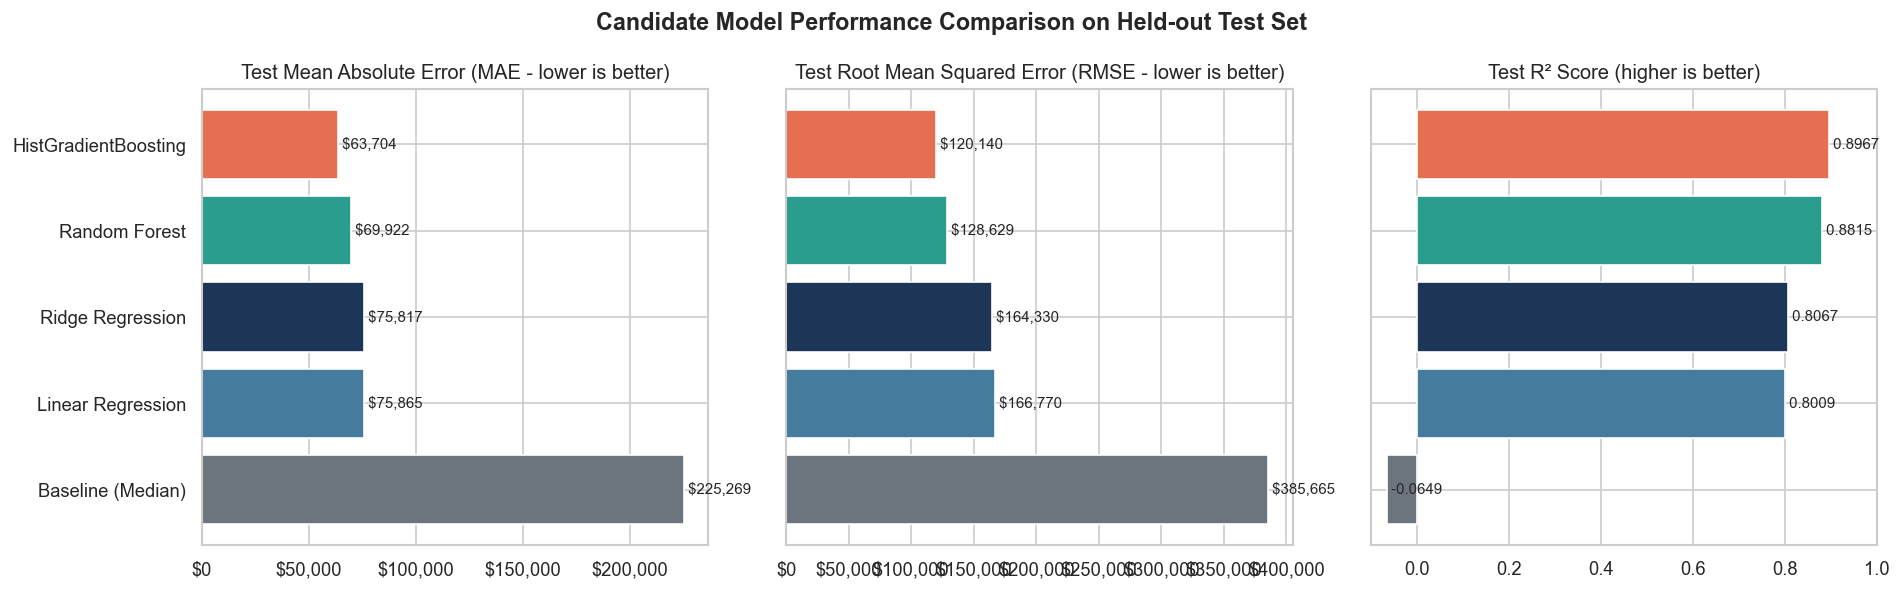

Winning Model Residual Diagnostics:


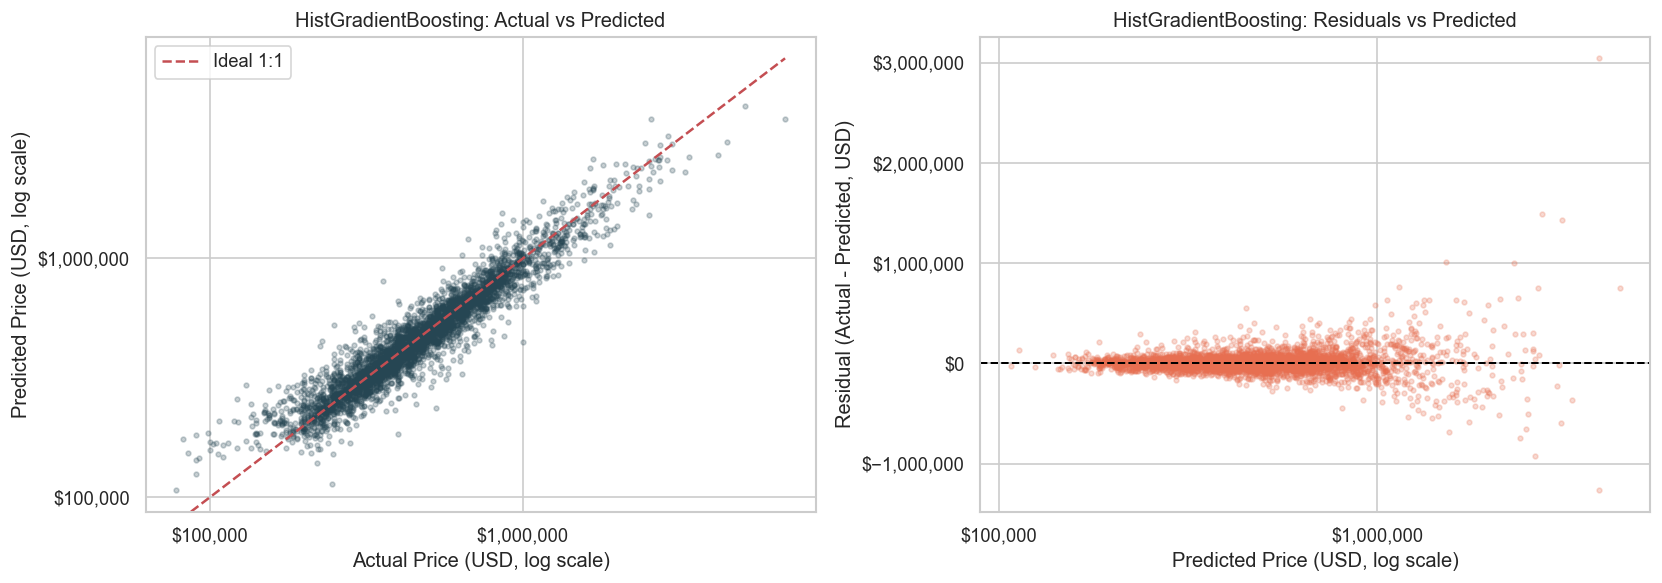

In [6]:
from IPython.display import Image, display

print("Candidate Model Comparison Chart:")
display(Image(filename=str(config.FIGURES_DIR / "11_model_performance_comparison.png")))

print("Winning Model Residual Diagnostics:")
display(Image(filename=str(config.FIGURES_DIR / "12_model_residuals_diagnostic.png")))

## 7. Model Verification & Inference Test

In [7]:
# Load the serialized production pipeline and predict on a sample
loaded_model = predict.load_model(config.SAVED_MODEL_PATH)
sample_properties = X_test.head(5)
sample_predictions = predict.predict_price(loaded_model, sample_properties)

comparison_sample = pd.DataFrame({
    "Actual Price": y_test.head(5).values,
    "Predicted Price": sample_predictions,
    "Absolute Error ($)": np.abs(y_test.head(5).values - sample_predictions)
})
display(comparison_sample)

,Actual Price,Predicted Price,Absolute Error ($)
0,"510,000.00","493,213.81","16,786.19"
1,"395,000.00","374,547.35","20,452.65"
2,"233,000.00","223,204.51","9,795.49"
3,"696,000.00","705,332.17","9,332.17"
4,"309,000.00","222,092.38","86,907.62"


## 8. Summary & Next Steps

### Key Results
1. **Baseline Model (Median Price)**:
   - MAE: **$225,269** | RMSE: **$385,665** | R²: **-0.0649**
2. **Linear Regression & Ridge Regression**:
   - Ridge MAE: **$75,817** | RMSE: **$164,330** | R²: **0.8067** (Substantial improvement over baseline; stable and interpretable).
3. **Random Forest Regressor**:
   - MAE: **$69,922** | RMSE: **$128,629** | R²: **0.8815**
4. **HistGradientBoosting Regressor (Winning Model)**:
   - MAE: **$63,704** | RMSE: **$120,140** | R²: **0.8967**
   - Achieves the lowest error across all metrics while keeping artifact size lightweight (~560 KB).

**Artifacts Generated**:
- Model pipeline: `models/price_model.joblib`
- Metrics: `models/model_metrics.json`
- Figures: `reports/figures/11_model_performance_comparison.png`, `reports/figures/12_model_residuals_diagnostic.png`
